In [1]:
import glob
import numpy as np
import pandas as pd
import xarray as xr 
import seaborn as sns
import matplotlib.pyplot as plt

time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)


def calculate_djf_mean(ds):
    ds_seasons = ds.resample(time='QE-FEB').mean()
    ds_djf = ds_seasons.sel(time=(ds_seasons['time.season'] == 'DJF'))
    return ds_djf

def calculate_tercile_flags(data, var):
    # calculate terciles to cluster indices into 3 categories: -1 (negative/cold), 0 (netural), 1 (positive/warm state)
    df = data[var].to_dataframe()
    df = df.reset_index()
    df = df.set_index('time')
    tertiles = df[var].quantile([1/3, 2/3]).to_list()
    tertiles = [-float('inf')] + tertiles + [float('inf')]

    return tertiles

In [2]:
df_flags = pd.read_csv("/home/kperny/VolMIP_stratosphere/tab/nao_enso_flags.csv")
plotdir = "/home/kperny/VolMIP_stratosphere/plots/"

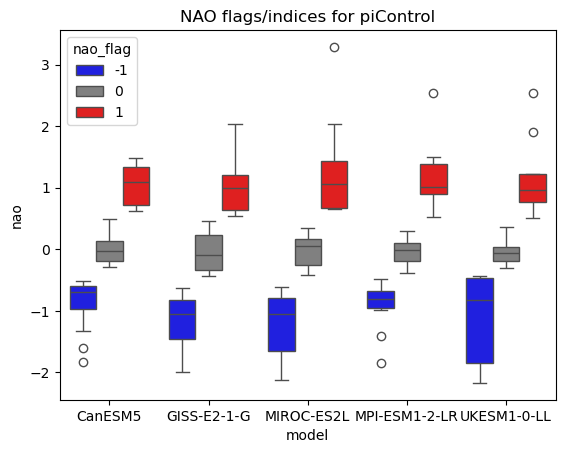

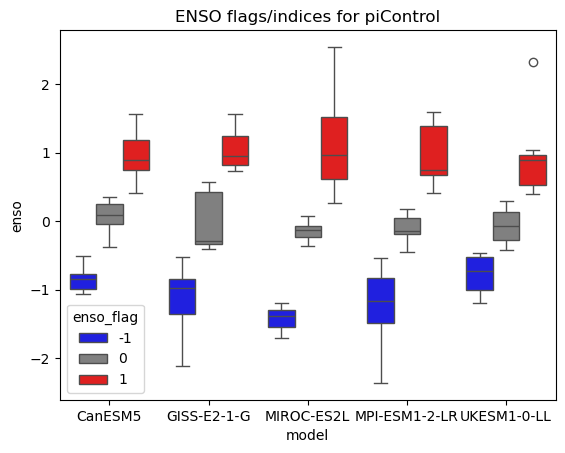

In [3]:
sns.boxplot(x="model", y="nao",
            hue="nao_flag", palette=["b", "grey", "r"],
            data=df_flags)
plt.title('NAO flags/indices for piControl')
plt.savefig(plotdir + 'background/enso_flags-indices.png', dpi=200)
plt.show()
sns.boxplot(x="model", y="enso",
            hue="enso_flag", palette=["b", "grey", "r"],
            data=df_flags)
plt.title('ENSO flags/indices for piControl')
plt.savefig(plotdir + 'background/enso_flags-indices.png', dpi=200)

In [15]:
datadir + 'pinatubo-full/' + model + '/NAO_*' + ens + '*_fixed_dates.nc'

'/sto4/data/Intermediate/VolMIP/pinatubo-full/GISS-E2-1-G/NAO_*r10i1p1f2*_fixed_dates.nc'

/tmp/ipykernel_792903/3550080402.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cut['experiment'] = 'piControl'


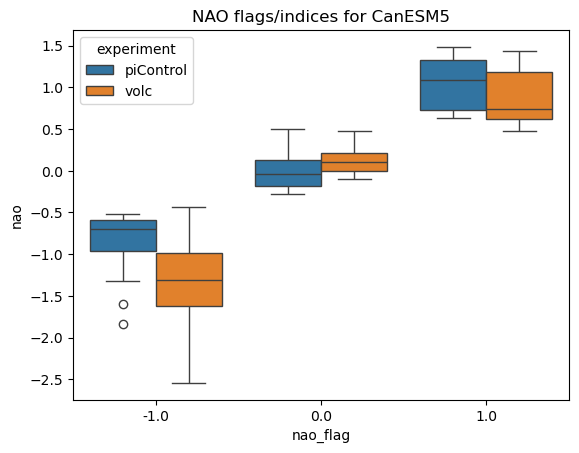

/tmp/ipykernel_792903/3550080402.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cut['experiment'] = 'piControl'


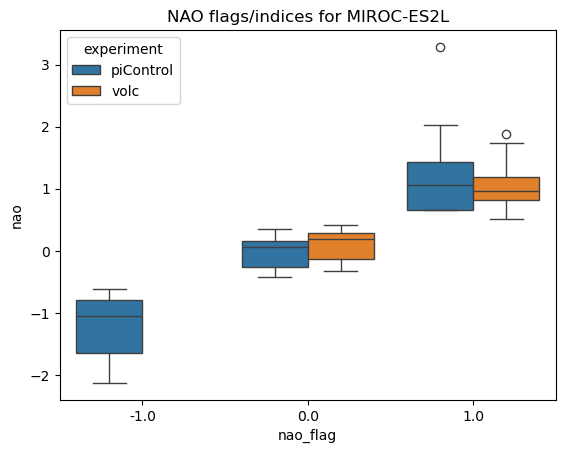

/tmp/ipykernel_792903/3550080402.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cut['experiment'] = 'piControl'


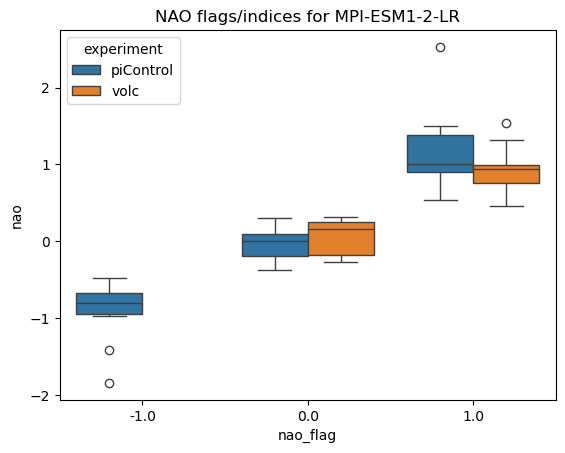

/tmp/ipykernel_792903/3550080402.py:12: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  data_volc = xr.open_dataset(glob.glob(datadir + 'pinatubo-full/' + model + '/NAO_*' + ens + '*_fixed_dates.nc')[0])
/tmp/ipykernel_792903/3550080402.py:12: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  data_volc = xr.open_dataset(glob.glob(datadir + 'pinatubo-full/' + model + '/NAO_*' + ens + '*_fixed_dates.nc')[0])
/tmp/ipykernel_792903/3550080402.py:12: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime object

IndexError: list index out of range

In [ ]:
datadir = "/sto4/data/Intermediate/VolMIP/"
models = ['CanESM5', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'GISS-E2-1-G'] #, 'UKESM1-0-LL']

collect_df = []
for model in models:
    df_model = df_flags.where(df_flags['model'] == model).dropna()

    data_control = xr.open_dataset(glob.glob(datadir + 'piControl/' + model + '/piControl_' + model + '_NAO_*.nc')[0], decode_times=time_coder)
    tertiles = calculate_tercile_flags((data_control- data_control.mean('time') ) /  np.sqrt(data_control.var('time')), 'zg')
    nao = []
    for ens in df_model['realization']:
        data_volc = xr.open_dataset(glob.glob(datadir + 'pinatubo-full/' + model + '/NAO_*' + ens + '*_fixed_dates.nc')[0])
        nao.append((calculate_djf_mean(data_volc).sel(time='1992') - data_control.mean('time') ) /  np.sqrt(data_control.var('time')))
        
    nao_volc = xr.concat(nao, dim='realization')
    nao_volc['realization'] = df_model['realization'].values
    df_volc = nao_volc.rename({'zg': 'nao'}).nao.to_dataframe().reset_index().drop(['time', 'plev', 'lat', 'lon'], axis=1)

    df_volc['nao_flag'] = pd.cut(df_volc['nao'], bins=tertiles, labels=[-1,0,1])
    df_volc['experiment'] = 'volc'
    df_cut = df_model[['realization', 'nao', 'nao_flag']]
    df_cut['experiment'] = 'piControl'

    df = pd.concat([df_cut, df_volc])
    df['model'] = model
    collect_df.append(df)

    sns.boxplot(x="nao_flag", y="nao",
                hue="experiment", palette=['C0', 'C1'],
                data=df)
    plt.title('NAO flags/indices for ' + model)
    plt.savefig(plotdir + model + '_nao-change.png', dpi=200)
    plt.show()

In [ ]:
df = pd.concat(collect_df)
df.to_csv("/home/kperny/VolMIP_stratosphere/tab/")

In [37]:
df = df.set_index(['model', 'realization', 'experiment']).sort_index()

In [42]:
df.reset_index().to_csv("/home/kperny/VolMIP_stratosphere/tab/nao_change.csv", index=False)